# CityPulse Analytics Arena — sab_team

**Team:** Adam Kowalczyk · Bartosz Sieradzki · Oleksandr Shybistkyi

Mission: find **when, where and why** traffic problems occur, and prove every conclusion.

Run top to bottom (`Kernel → Restart & Run All`). Raw CSVs in `data/` are never modified;
shared loading / integration / dashboard code lives in `dashboard.py`. Charts are saved to `figures/`.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from dashboard import load_data, integrate_data, city_dashboard, SEVERITY_SCORE, PEAK_HOURS

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

traffic, sensors, weather, incidents = load_data()
{name: len(df) for name, df in
 dict(traffic=traffic, sensors=sensors, weather=weather, incidents=incidents).items()}

{'traffic': 13392, 'sensors': 18, 'weather': 4446, 'incidents': 130}

## Round 1 — Data Integration
*Owner: Bartosz Sieradzki (Data Engineer)*

| Table | Grain (one row = …) | Unique key |
|---|---|---|
| traffic | one sensor in one hour | (timestamp, sensor_id) |
| sensors | one sensor | sensor_id |
| weather | one district in one hour | (timestamp, district) |
| incidents | one incident event | incident_id; join key (timestamp, sensor_id) |

### 1.1 Key uniqueness checks (before any merge)

In [2]:
pd.Series({
    "traffic dup (timestamp, sensor_id)": traffic.duplicated(["timestamp", "sensor_id"]).sum(),
    "sensors dup sensor_id": sensors["sensor_id"].duplicated().sum(),
    "weather dup (timestamp, district)": weather.duplicated(["timestamp", "district"]).sum(),
    "incidents dup incident_id": incidents["incident_id"].duplicated().sum(),
    "incidents dup (timestamp, sensor_id)": incidents.duplicated(["timestamp", "sensor_id"]).sum(),
}, name="duplicate_keys").to_frame()

,duplicate_keys
"traffic dup (timestamp, sensor_id)",0
sensors dup sensor_id,0
"weather dup (timestamp, district)",0
incidents dup incident_id,0
"incidents dup (timestamp, sensor_id)",0


All keys are unique → sensors and weather are `many_to_one` joins, and incidents is `one_to_one`
(at most one incident per sensor-hour, so the incident join cannot multiply traffic rows).

### 1.2 Merge pipeline (left joins, `validate=`, named indicators)
Step by step, printing `len()` before and after every merge:

In [3]:
print("traffic rows:", len(traffic))

step1 = traffic.merge(sensors, on="sensor_id", how="left",
                      validate="many_to_one", indicator="sensor_match")
print("after + sensors:  ", len(step1), step1["sensor_match"].value_counts().to_dict())

step2 = step1.merge(weather, on=["timestamp", "district"], how="left",
                    validate="many_to_one", indicator="weather_match")
print("after + weather:  ", len(step2), step2["weather_match"].value_counts().to_dict())

step3 = step2.merge(incidents, on=["timestamp", "sensor_id"], how="left",
                    validate="one_to_one", indicator="incident_match")
print("after + incidents:", len(step3), step3["incident_match"].value_counts().to_dict())

assert len(step1) == len(step2) == len(step3) == len(traffic)

traffic rows: 13392
after + sensors:   13392 {'both': 13392, 'left_only': 0, 'right_only': 0}
after + weather:   13392 {'both': 13338, 'left_only': 54, 'right_only': 0}
after + incidents: 13392 {'left_only': 13265, 'both': 127, 'right_only': 0}


The same pipeline is packaged as `integrate_data()` in `dashboard.py`. It adds helper columns (date, hour, peak flag, severity score) and the anti-join reports. We use that version from here on:

In [4]:
data, report = integrate_data(traffic, sensors, weather, incidents)
assert len(data) == len(step3) and (data["incident_id"].notna().sum() == step3["incident_id"].notna().sum())
pd.DataFrame({
    "sensor_match": report["sensor_match"],
    "weather_match": report["weather_match"],
    "incident_match": report["incident_match"],
}).fillna(0).astype(int)

traffic rows before:        13392
after + sensors:            13392
after + weather:            13392
after + incidents:          13392
weather hours missing:      18
incidents, unknown sensor:  3


,sensor_match,weather_match,incident_match
both,13392,13338,127
left_only,0,54,13265
right_only,0,0,0


### 1.3 Unmatched records — investigated, not dropped

In [5]:
print("Weather hours missing from weather.csv (each one affects 3 sensors = 3 traffic rows):")
report["missing_weather_hours"]

Weather hours missing from weather.csv (each one affects 3 sensors = 3 traffic rows):


,timestamp,district
0,2026-10-15 22:00:00,University
1,2026-10-18 02:00:00,Riverside
2,2026-10-18 10:00:00,Riverside
3,2026-10-19 16:00:00,Old Town
4,2026-10-23 20:00:00,Riverside
5,2026-10-28 16:00:00,Industrial
6,2026-10-29 21:00:00,Old Town
7,2026-10-31 22:00:00,Airport
8,2026-11-01 10:00:00,Riverside
9,2026-11-02 23:00:00,Riverside


In [6]:
print("Incidents that reference a sensor_id not in sensors.csv:")
report["unknown_sensor_incidents"]

Incidents that reference a sensor_id not in sensors.csv:


,incident_id,timestamp,sensor_id,incident_type,severity,duration_min,lanes_blocked
0,INC-ORPHAN-001,2026-10-22 08:00:00,S-099,debris_on_road,moderate,25,1
1,INC-ORPHAN-002,2026-11-03 17:00:00,S-098,vehicle_breakdown,low,18,0
2,INC-ORPHAN-003,2026-11-10 11:00:00,S-097,minor_collision,high,40,1


### 1.4 What if a right-hand key were duplicated?

In [7]:
bad_sensors = pd.concat([sensors, sensors[sensors.sensor_id == "S-001"]])  # S-001 listed twice
exploded = traffic.merge(bad_sensors, on="sensor_id", how="left")
print("rows before:", len(traffic), "| rows after:", len(exploded),
      "| extra rows:", len(exploded) - len(traffic))
try:
    traffic.merge(bad_sensors, on="sensor_id", how="left", validate="many_to_one")
except pd.errors.MergeError as e:
    print("validate= caught it ->", e)

rows before: 13392 | rows after: 14136 | extra rows: 744
validate= caught it -> Merge keys are not unique in right dataset; not a many-to-one merge

Duplicates in right:
 sensor_id
    S-001 ...


**Round 1 answers**
- Traffic observations: **13,392 before and 13,392 after** all three merges (asserted in `integrate_data`) — no row explosion, no silent loss.
- Weather: **18 district-hours are missing** from weather.csv → **54 traffic rows** have `weather_match = left_only` (kept, weather columns NaN). No weather row is left unused (`right_only = 0`).
- Incidents: **127 of 130** attach to a traffic row. The other **3 reference unknown sensors S-097, S-098, S-099** (INC-ORPHAN-001…003). They are kept in the raw incidents table and reported, not deleted.
- A duplicated right-hand key would silently copy every matching left row (744 extra rows for one duplicated sensor). `validate="many_to_one"` turns that into an error instead.

## Round 2 — Traffic Hotspot
*Owner: Oleksandr Shybistkyi (Traffic Analyst)*

Severity mapping (ordinal, documented): `low = 1, moderate = 2, high = 3, critical = 4`.
Peak hours = 07–09 and 16–18 (the clear rush-hour blocks in the hourly profile, Round 3).

Note: `size()` counts rows, while `count()` counts non-null values. We use `count` on `incident_id` so that traffic hours without an incident are not counted as incidents.

In [8]:
# Incidents per district/road: use the raw incidents table joined to sensors (unknown sensors have no district)
inc = incidents.merge(sensors, on="sensor_id", how="left", validate="many_to_one")
inc["severity_score"] = inc["severity"].map(SEVERITY_SCORE)

peak = (data.groupby(["district", "is_peak"])["vehicle_count"].mean()
        .unstack().rename(columns={True: "peak_avg_vehicles", False: "offpeak_avg_vehicles"}))
peak["peak_minus_offpeak"] = peak["peak_avg_vehicles"] - peak["offpeak_avg_vehicles"]

district_report = (
    data.groupby("district")
        .agg(sensors=("sensor_id", "nunique"),
             avg_vehicles=("vehicle_count", "mean"),
             avg_speed_kmh=("avg_speed_kmh", "mean"),
             observations=("sensor_id", "size"))
        .join(inc.groupby("district").agg(incidents=("incident_id", "count"),
                                          avg_severity=("severity_score", "mean")))
        .join(peak)
        .sort_values("avg_vehicles", ascending=False)
        .round(2).reset_index()
)
district_report

,district,sensors,avg_vehicles,avg_speed_kmh,observations,incidents,avg_severity,offpeak_avg_vehicles,peak_avg_vehicles,peak_minus_offpeak
0,Central,3,74.57,42.52,2232,16,2.12,55.43,131.97,76.53
1,Riverside,3,64.13,36.32,2232,31,2.10,47.93,112.74,64.81
2,University,3,61.50,36.53,2232,16,1.88,45.88,108.35,62.47
3,Industrial,3,56.39,39.09,2232,26,2.23,42.08,99.34,57.26
4,Airport,3,52.48,42.26,2232,18,2.00,39.01,92.89,53.88
5,Old Town,3,42.84,30.39,2232,20,2.10,31.82,75.90,44.08


In [9]:
road_report = (
    data.groupby(["road_name", "district", "road_type"])
        .agg(avg_vehicles=("vehicle_count", "mean"),
             avg_speed_kmh=("avg_speed_kmh", "mean"),
             speed_limit_kmh=("speed_limit_kmh", "first"))
        .join(inc.groupby("road_name").agg(incidents=("incident_id", "count"),
                                           avg_severity=("severity_score", "mean"),
                                           critical_or_high=("severity", lambda s: s.isin(["high", "critical"]).sum())),
              on="road_name")
        .assign(speed_pct_of_limit=lambda d: d.avg_speed_kmh / d.speed_limit_kmh * 100)
        .round(2).reset_index()
)
print("Busiest roads"); display(road_report.nlargest(5, "avg_vehicles")[["road_name", "district", "avg_vehicles"]])
print("Slowest roads (absolute km/h)"); display(road_report.nsmallest(5, "avg_speed_kmh")[["road_name", "road_type", "avg_speed_kmh", "speed_limit_kmh", "speed_pct_of_limit"]])
print("Incident hotspots"); display(road_report.sort_values(["incidents", "avg_severity"], ascending=False).head(5)[["road_name", "district", "incidents", "critical_or_high", "avg_severity"]])
print("Highest average severity"); display(road_report.sort_values("avg_severity", ascending=False).head(5)[["road_name", "district", "incidents", "avg_severity"]])

Busiest roads


,road_name,district,avg_vehicles
4,Central Boulevard,Central,74.71
10,Main Avenue,Central,74.50
11,Market Street,Central,74.49
0,Bridge Road,Riverside,64.29
14,Riverbank Avenue,Riverside,64.07


Slowest roads (absolute km/h)


,road_name,road_type,avg_speed_kmh,speed_limit_kmh,speed_pct_of_limit
7,Historic Lane,local,27.70,30,92.32
12,Museum Road,local,27.75,30,92.50
13,Quay Street,local,27.99,40,69.98
8,Library Road,local,28.04,40,70.11
14,Riverbank Avenue,collector,35.65,50,71.30


Incident hotspots


,road_name,district,incidents,critical_or_high,avg_severity
13,Quay Street,Riverside,12,4,2.25
0,Bridge Road,Riverside,11,2,1.64
6,Factory Road,Industrial,10,3,2.20
15,Runway Access,Airport,10,2,2.20
12,Museum Road,Old Town,9,6,2.78


Highest average severity


,road_name,district,incidents,avg_severity
12,Museum Road,Old Town,9,2.78
14,Riverbank Avenue,Riverside,8,2.50
10,Main Avenue,Central,7,2.43
9,Logistics Avenue,Industrial,7,2.29
13,Quay Street,Riverside,12,2.25


In [10]:
severity_by_type = (inc.groupby(["incident_type", "severity"]).size().unstack(fill_value=0)
                       .reindex(columns=list(SEVERITY_SCORE), fill_value=0))
severity_by_type.assign(total=severity_by_type.sum(axis=1)).sort_values("total", ascending=False)

severity,low,moderate,high,critical,total
incident_type,,,,,
minor_collision,9,9,9,2,29
vehicle_breakdown,9,10,8,1,28
debris_on_road,9,13,3,1,26
road_closure,4,9,4,2,19
traffic_signal_failure,2,8,5,2,17
multi_vehicle_collision,3,2,1,1,7
pedestrian_incident,1,3,0,0,4


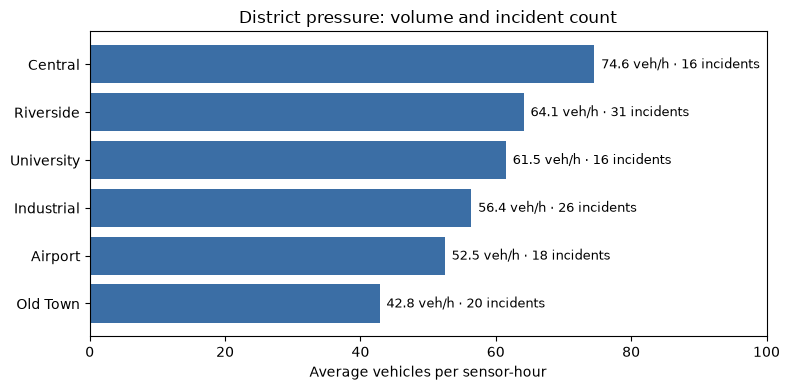

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
d = district_report.sort_values("avg_vehicles")
ax.barh(d["district"], d["avg_vehicles"], color="#3b6ea5")
for y, (v, n) in enumerate(zip(d["avg_vehicles"], d["incidents"])):
    ax.text(v + 1, y, f"{v:.1f} veh/h · {n} incidents", va="center", fontsize=9)
ax.set_xlabel("Average vehicles per sensor-hour"); ax.set_xlim(0, 100)
ax.set_title("District pressure: volume and incident count")
fig.tight_layout(); fig.savefig(FIG / "district_ranking.png", dpi=150); plt.show()

**Round 2 answers**
1. Highest average hourly vehicle count: **Central** (74.6 vehicles per sensor-hour).
2. Lowest average speed: **Old Town** (30.4 km/h). This is expected, since its roads have 30–40 km/h limits.
3. Busiest roads: **Central Boulevard, Main Avenue, Market Street** (all in Central, ≈ 74.5 veh/h).
4. Most recorded incidents: **Riverside** (31 incidents). Its Quay Street (12) and Bridge Road (11) are the top two incident roads.
5. Highest average severity: **Museum Road**, Old Town (2.78 on the 1–4 scale).
6. Largest peak vs off-peak difference: **Central**. Its peak hours carry the most extra vehicles compared with off-peak.

## Round 3 — Time Series
*Owner: Adam Kowalczyk (Time Series Analyst)*

In [12]:
ts = data.sort_values("timestamp").set_index("timestamp")

daily = ts.resample("D").agg({"vehicle_count": "sum", "avg_speed_kmh": "mean"})
daily["vehicles_3day_ma"] = daily["vehicle_count"].rolling(3).mean()
daily["abs_change"] = daily["vehicle_count"].diff()
daily["pct_change"] = daily["vehicle_count"].pct_change() * 100
daily["prev_day_vehicles"] = daily["vehicle_count"].shift(1)
daily["weekday"] = daily.index.day_name()
daily.round(1)

,vehicle_count,avg_speed_kmh,vehicles_3day_ma,abs_change,pct_change,prev_day_vehicles,weekday
timestamp,,,,,,,
2026-10-15,27775,38.0,NaN,NaN,NaN,NaN,Thursday
2026-10-16,27764,37.8,NaN,-11.0,-0.0,27775.0,Friday
2026-10-17,19306,38.0,24948.3,-8458.0,-30.5,27764.0,Saturday
2026-10-18,19529,37.7,22199.7,223.0,1.2,19306.0,Sunday
2026-10-19,27550,38.0,22128.3,8021.0,41.1,19529.0,Monday
2026-10-20,27559,37.9,24879.3,9.0,0.0,27550.0,Tuesday
2026-10-21,27847,37.9,27652.0,288.0,1.0,27559.0,Wednesday
2026-10-22,27534,37.7,27646.7,-313.0,-1.1,27847.0,Thursday
2026-10-23,27897,37.7,27759.3,363.0,1.3,27534.0,Friday


In [13]:
district_daily_speed = (ts.groupby("district")["avg_speed_kmh"].resample("D").mean()
                          .unstack(0).round(2))
district_daily_speed.tail(7)

district,Airport,Central,Industrial,Old Town,Riverside,University
timestamp,,,,,,
2026-11-08,41.96,42.91,39.40,30.78,35.70,36.42
2026-11-09,42.15,42.32,39.13,30.67,36.68,35.61
2026-11-10,41.98,42.93,38.99,30.30,36.45,36.43
2026-11-11,42.74,42.55,38.97,30.75,36.91,36.51
2026-11-12,42.15,43.46,38.71,30.08,33.28,36.74
2026-11-13,41.79,42.61,39.36,30.32,36.07,36.37
2026-11-14,42.26,42.51,39.07,30.60,36.73,37.08


In [14]:
by_hour = data.groupby("hour").agg(total_vehicles=("vehicle_count", "sum"),
                                   avg_speed_kmh=("avg_speed_kmh", "mean"))
busiest_hour = by_hour["total_vehicles"].idxmax()
slowest_day = daily["avg_speed_kmh"].idxmin()
print(f"Busiest hour of day: {busiest_hour}:00 ({by_hour.loc[busiest_hour, 'total_vehicles']:,} vehicles in 31 days)")
print(f"Day with lowest citywide average speed: {slowest_day.date()} ({daily.loc[slowest_day, 'avg_speed_kmh']:.2f} km/h)")
print("Biggest day-to-day increase:", daily["pct_change"].idxmax().date(), f"{daily['pct_change'].max():+.1f}%")
print("Biggest day-to-day decrease:", daily["pct_change"].idxmin().date(), f"{daily['pct_change'].min():+.1f}%")

Busiest hour of day: 17:00 (59,597 vehicles in 31 days)
Day with lowest citywide average speed: 2026-11-12 (37.40 km/h)
Biggest day-to-day increase: 2026-11-09 +44.9%
Biggest day-to-day decrease: 2026-10-17 -30.5%


In [15]:
# Weekday vs weekend: compare per day AND per hour of day (controls for time-of-day)
day_type = daily.assign(day_type=pd.Series(daily.index.day_of_week >= 5, index=daily.index)
                        .map({True: "weekend", False: "weekday"}))
display(day_type.groupby("day_type").agg(days=("vehicle_count", "size"),
                                         avg_daily_vehicles=("vehicle_count", "mean"),
                                         avg_speed_kmh=("avg_speed_kmh", "mean")).round(1))

hourly_profile = (data.assign(day_type=data["is_weekend"].map({True: "weekend", False: "weekday"}))
                      .groupby(["hour", "day_type"])["vehicle_count"].mean().unstack())
hourly_profile.round(1).T

,days,avg_daily_vehicles,avg_speed_kmh
day_type,,,
weekday,22,27736.8,37.8
weekend,9,19472.0,37.9


hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
day_type,,,,,,,,,,,,,,,,,,,,,,,,
weekday,14.2,14.1,14.1,14.2,14.2,14.1,70.8,109.9,109.6,110.4,74.4,74.4,74.1,74.0,74.5,74.3,116.2,117.1,116.7,71.5,39.0,39.1,39.0,70.9
weekend,9.9,9.9,10.0,9.9,9.9,9.8,50.0,77.2,77.8,77.1,51.7,53.1,51.7,53.0,52.1,52.5,81.9,81.7,82.0,49.5,27.2,27.2,27.1,49.5


In [16]:
# Unusual days vs the rolling average: citywide daily speed against a centred 7-day rolling mean
# (7 days, so every window contains a full week and weekends do not distort it)
daily["speed_7day_ma"] = daily["avg_speed_kmh"].rolling(7, center=True, min_periods=4).mean()
daily["speed_vs_ma"] = daily["avg_speed_kmh"] - daily["speed_7day_ma"]
daily.nsmallest(3, "speed_vs_ma")[["weekday", "avg_speed_kmh", "speed_7day_ma", "speed_vs_ma"]].round(2)

,weekday,avg_speed_kmh,speed_7day_ma,speed_vs_ma
timestamp,,,,
2026-11-12,Thursday,37.40,37.81,-0.41
2026-11-02,Monday,37.67,37.84,-0.17
2026-10-18,Sunday,37.73,37.89,-0.16


In [17]:
# Drill down: compare each district's daily speed with its own typical level (median, robust to the anomaly)
dev = district_daily_speed - district_daily_speed.median()
z = dev / district_daily_speed.std()
unusual = (z.stack().rename("z_score").reset_index()
             .query("abs(z_score) > 3").sort_values("z_score"))
unusual.assign(speed_kmh=[district_daily_speed.loc[r.timestamp, r.district] for r in unusual.itertuples()]).round({"z_score": 2, "speed_kmh": 2})

,timestamp,district,z_score,speed_kmh
172,2026-11-12,Riverside,-4.8,33.28


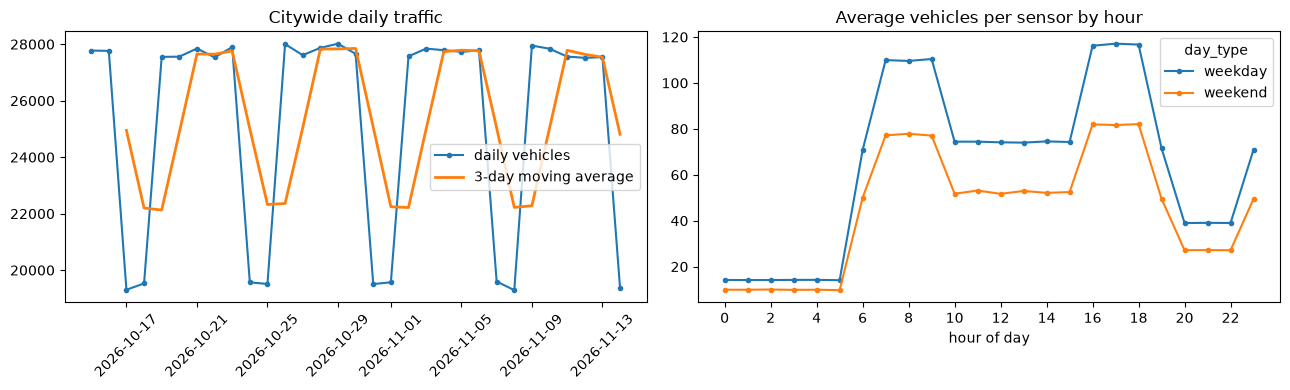

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.plot(daily.index, daily["vehicle_count"], marker="o", ms=3, label="daily vehicles")
ax.plot(daily.index, daily["vehicles_3day_ma"], lw=2, label="3-day moving average")
ax.set_title("Citywide daily traffic"); ax.legend(); ax.tick_params(axis="x", rotation=45)
ax = axes[1]
hourly_profile.plot(ax=ax, marker="o", ms=3)
ax.set_title("Average vehicles per sensor by hour"); ax.set_xlabel("hour of day"); ax.set_xticks(range(0, 24, 2))
fig.tight_layout(); fig.savefig(FIG / "time_series.png", dpi=150); plt.show()

**Round 3 answers**
- Busiest hour: **17:00**. The evening peak (16–18) is slightly busier than the morning peak (07–09).
- Lowest citywide average speed: **12 November 2026** (37.40 km/h, compared with ≈ 37.9 on a normal day). This is the first hint of the mystery.
- Weekdays carry ≈ **27.7k vehicles per day**, and weekends ≈ **19.5k (−30%)**. The hourly profile shows that weekends have lower volume in the rush-hour blocks. Night traffic stays almost the same.
- Largest changes: every Monday jumps **+41–45 %** and every Saturday drops **≈ −30 %**. This is the weekly cycle, not an anomaly.
- Unusual period vs the rolling average: **12 Nov** has the lowest citywide speed compared with its 7-day rolling mean (−0.41 km/h, more than twice the next day's gap). Drilling down by district, only **Riverside on 12 Nov** is more than 3 standard deviations from normal. Its daily speed fell to 33.3 km/h while its usual level is ≈ 36.5.

## Round 4 — The Traffic Mystery
*Shared by all three members: Adam (baseline + weather), Oleksandr (roads + traffic evidence), Bartosz (incident evidence)*

> "On 12 November 2026, traffic speed suddenly dropped by approximately 45% in one district."

### Step 1 — FIND the district and time window

In [19]:
EVENT = pd.Timestamp("2026-11-12")
# Fair baseline: same hours on nearby, non-event WEEKDAYS (12 Nov 2026 is a Thursday; weekends excluded).
BASELINE_DAYS = pd.to_datetime(["2026-11-05", "2026-11-06", "2026-11-09", "2026-11-10", "2026-11-11", "2026-11-13"])
print("Event day:", EVENT.day_name(), "| baseline days:", [d.strftime("%a %d %b") for d in BASELINE_DAYS])

def hourly_speed(frame, days):
    return frame[frame["date"].isin(days)].groupby(["district", "hour"])["avg_speed_kmh"].mean()

event_h = hourly_speed(data, [EVENT])
base_h = hourly_speed(data, BASELINE_DAYS)
drop = ((base_h - event_h) / base_h * 100).unstack(0).round(1)   # rows = hour, columns = district
drop

Event day: Thursday | baseline days: ['Thu 05 Nov', 'Fri 06 Nov', 'Mon 09 Nov', 'Tue 10 Nov', 'Wed 11 Nov', 'Fri 13 Nov']


district,Airport,Central,Industrial,Old Town,Riverside,University
hour,,,,,,
0,5.5,-3.3,-1.8,-4.1,-2.6,-2.9
1,5.5,-1.0,-3.1,-2.4,-0.1,1.0
2,5.8,-1.6,5.2,1.4,-6.0,-0.8
3,8.7,2.9,-2.4,1.2,1.2,-1.8
4,3.1,-7.5,11.1,2.2,-6.2,-2.5
5,1.2,-3.5,-5.9,-1.5,-1.3,-0.1
6,0.6,1.1,0.2,-8.5,-0.4,-6.0
7,-8.0,3.8,9.1,0.2,45.5,3.7
8,2.1,7.9,4.3,-7.0,39.3,13.6


In [20]:
district_hit = drop.max().idxmax()
window = drop.index[drop[district_hit] > 25]
print(f"District: {district_hit} | hours with >25% speed drop: {window.min()}:00 – {window.max()}:59")
WINDOW = list(window)

District: Riverside | hours with >25% speed drop: 7:00 – 12:59


### Step 2 — COMPARE with the baseline (same hours, same district)

In [21]:
def window_stats(days):
    sel = data[(data["district"] == district_hit) & data["date"].isin(days) & data["hour"].isin(WINDOW)]
    return pd.Series({"avg_speed_kmh": sel["avg_speed_kmh"].mean(), "avg_vehicles": sel["vehicle_count"].mean()})

compare = pd.DataFrame({"baseline": window_stats(BASELINE_DAYS), "12 Nov": window_stats([EVENT])})
compare["pct_change"] = (compare["12 Nov"] - compare["baseline"]) / compare["baseline"] * 100
compare.round(1)

,baseline,12 Nov,pct_change
avg_speed_kmh,34.9,19.7,-43.6
avg_vehicles,101.4,78.4,-22.7


In [22]:
# Control: other districts in the same window on the same day
others = pd.DataFrame({
    d: [drop.loc[WINDOW, d].mean()] for d in drop.columns
}, index=["avg speed drop % in window"]).T.sort_values("avg speed drop % in window", ascending=False)
others.round(1)

,avg speed drop % in window
Riverside,43.6
Old Town,2.0
University,1.2
Industrial,0.2
Central,-1.0
Airport,-4.0


### Step 3 — LOCALISE: rank roads by speed drop

In [23]:
sel = data[(data["district"] == district_hit) & data["hour"].isin(WINDOW)]
road_drop = pd.DataFrame({
    "baseline_speed": sel[sel["date"].isin(BASELINE_DAYS)].groupby("road_name")["avg_speed_kmh"].mean(),
    "event_speed": sel[sel["date"] == EVENT].groupby("road_name")["avg_speed_kmh"].mean(),
})
road_drop["speed_drop_pct"] = (road_drop["baseline_speed"] - road_drop["event_speed"]) / road_drop["baseline_speed"] * 100
road_drop = road_drop.sort_values("speed_drop_pct", ascending=False).round(1).reset_index()
road_drop

,road_name,baseline_speed,event_speed,speed_drop_pct
0,Bridge Road,43.7,24.4,44.3
1,Quay Street,27.3,15.4,43.7
2,Riverbank Avenue,33.8,19.4,42.5


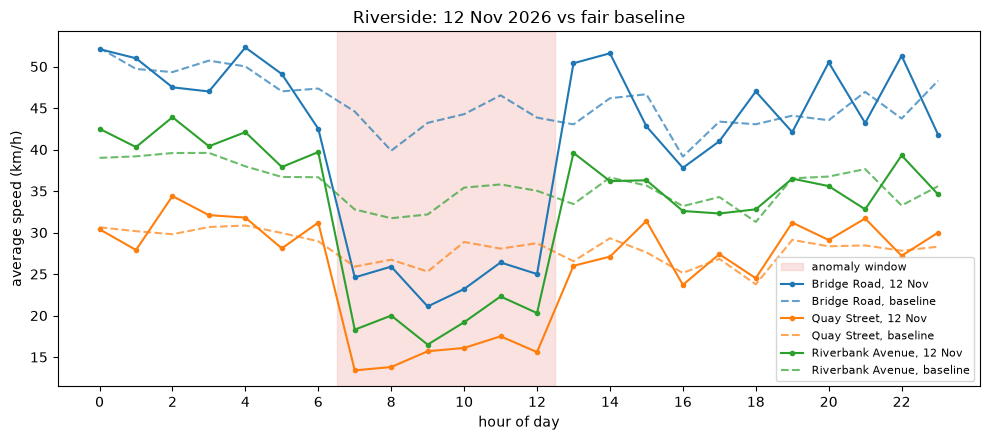

In [24]:
hourly_roads = (data[(data["district"] == district_hit) & (data["date"] == EVENT)]
                .pivot_table(index="hour", columns="road_name", values="avg_speed_kmh"))
base_roads = (data[(data["district"] == district_hit) & data["date"].isin(BASELINE_DAYS)]
              .pivot_table(index="hour", columns="road_name", values="avg_speed_kmh"))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.axvspan(min(WINDOW) - 0.5, max(WINDOW) + 0.5, color="#f4c7c3", alpha=0.5, label="anomaly window")
for road, colour in zip(hourly_roads, ["#1f77b4", "#ff7f0e", "#2ca02c"]):
    ax.plot(hourly_roads.index, hourly_roads[road], marker="o", ms=3, color=colour, label=f"{road}, 12 Nov")
    ax.plot(base_roads.index, base_roads[road], "--", color=colour, alpha=0.7, label=f"{road}, baseline")
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("hour of day"); ax.set_ylabel("average speed (km/h)")
ax.set_title(f"{district_hit}: 12 Nov 2026 vs fair baseline")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "mystery.png", dpi=150); plt.show()

### Step 4 — CROSS-CHECK weather and incidents

In [25]:
w = weather[weather["district"] == district_hit].assign(date=lambda d: d["timestamp"].dt.normalize(),
                                                      hour=lambda d: d["timestamp"].dt.hour)
w = w[w["hour"].isin(WINDOW)]
weather_check = pd.DataFrame({
    "baseline": w[w["date"].isin(BASELINE_DAYS)][["rainfall_mm", "wind_speed_kmh", "temperature_c"]].mean(),
    "12 Nov": w[w["date"] == EVENT][["rainfall_mm", "wind_speed_kmh", "temperature_c"]].mean(),
}).round(2)
display(weather_check)
print("12 Nov conditions in window:", w[w["date"] == EVENT]["weather_condition"].value_counts().to_dict())

,baseline,12 Nov
rainfall_mm,0.34,0.00
wind_speed_kmh,16.07,12.00
temperature_c,5.06,5.03


12 Nov conditions in window: {'Clear': 6}


In [26]:
inc_event = inc[(inc["timestamp"].dt.normalize() == EVENT)].sort_values("timestamp")
inc_event = inc_event.assign(end_time=inc_event["timestamp"] + pd.to_timedelta(inc_event["duration_min"], unit="m"))
inc_event[["incident_id", "timestamp", "end_time", "road_name", "district", "incident_type",
           "severity", "duration_min", "lanes_blocked"]]

,incident_id,timestamp,end_time,road_name,district,incident_type,severity,duration_min,lanes_blocked
101,INC-0102,2026-11-12 03:00:00,2026-11-12 03:59:00,Science Avenue,University,debris_on_road,low,59,0
124,INC-MYST-001,2026-11-12 07:00:00,2026-11-12 08:50:00,Bridge Road,Riverside,multi_vehicle_collision,critical,110,2
125,INC-MYST-002,2026-11-12 08:00:00,2026-11-12 09:35:00,Riverbank Avenue,Riverside,road_closure,high,95,1
126,INC-MYST-003,2026-11-12 09:00:00,2026-11-12 10:13:00,Quay Street,Riverside,traffic_signal_failure,high,73,0


In [27]:
# How unusual is this incident pattern? Riverside incidents in the window hours on all other days.
riv = inc[(inc["district"] == district_hit) & inc["timestamp"].dt.hour.isin(WINDOW)]
riv.groupby(riv["timestamp"].dt.normalize()).size().rename("incidents_in_window").sort_values(ascending=False).head(5)

timestamp
2026-11-12    3
2026-10-17    1
2026-10-20    1
2026-10-21    1
2026-10-26    1
Name: incidents_in_window, dtype: int64

### Step 5 — ARGUE

**Observed facts (evidence)**
1. **Traffic:** In **Riverside, 07:00–12:59 on Thu 12 Nov**, the average speed was **≈ 43 % below** the same hours on 6 nearby weekdays. All 3 Riverside roads dropped by a similar amount (Bridge Road, Riverbank Avenue, Quay Street). Speeds return to normal from 13:00. No other district dropped more than a few % in that window, so this was a local event and not citywide.
2. **Incidents:** Three **INC-MYST** incidents happened on three different Riverside roads, one per hour at the start of the window. These were a **critical multi-vehicle collision on Bridge Road at 07:00 (2 lanes blocked, 110 min)**, a **high-severity road closure on Riverbank Avenue at 08:00 (95 min)** and a **high-severity traffic-signal failure on Quay Street at 09:00 (73 min)**. No other day has more than one Riverside incident in these hours.
3. **Weather:** Riverside was **Clear, 0.0 mm rain** in the window. Wind was calmer than the baseline (12 vs 16 km/h) and the temperature was the same (≈ 5 °C). Weather does **not** explain the drop. Elsewhere in the data, rain lowers speed by only ≈ 3 km/h, which is far less than 43 %.
4. **Volume:** Vehicle counts also fell, from 101 to 78 vehicles per sensor-hour (**−23 %**, see the `compare` table). Speed and throughput fell together, which is the pattern of **blocked capacity** (lanes closed, queues). A demand surge would show more cars and lower speed instead.

**Hypothesis (interpretation):** A chain of incidents most likely caused the slowdown. The 07:00 collision on Bridge Road, the main arterial, came first. The road closure on Riverbank Avenue and the signal failure on Quay Street then removed the alternative routes. The congestion lasted until about 13:00, which is longer than the incidents themselves (the last one should have cleared by ≈ 10:15), because queues take time to clear.

**Limitation:** This is correlation in time and place, not proof of cause. We do not have queue-length, diversion or incident clearance data. The incident timestamps are rounded to the hour. Riverside wind speed is constant at 12 km/h for all of 12 Nov, which happens on no other district-day (1 of 186). This weather data may be interpolated and less reliable. The baseline uses only 6 days.

## Round 5 — Final Briefing & Dashboard
*Owner: Adam Kowalczyk (Team Lead / Reporter), with slides from the whole team*

The briefing is in `team_briefing.pdf` / `team_briefing.pptx`. The dashboard tables below come from `dashboard.city_dashboard()`.

In [28]:
dash = city_dashboard(traffic, sensors, weather, incidents)
for name, table in dash.items():
    print(f"\n=== {name} ({len(table)} rows) ===")
    display(table.head(10))


=== by_district (6 rows) ===


,district,total_vehicles,avg_vehicles_per_hour,avg_speed_kmh,observations,incidents
0,Central,166435,74.6,42.5,2232,16
1,Riverside,143138,64.1,36.3,2232,31
2,University,137259,61.5,36.5,2232,16
3,Industrial,125871,56.4,39.1,2232,26
4,Airport,117137,52.5,42.3,2232,18
5,Old Town,95617,42.8,30.4,2232,20



=== by_road (18 rows) ===


,road_name,district,road_type,avg_vehicles,avg_speed_kmh,speed_limit_kmh,incident_count,avg_severity
0,Central Boulevard,Central,arterial,74.71,45.71,60,5,1.80
1,Main Avenue,Central,arterial,74.50,45.87,60,7,2.43
2,Market Street,Central,collector,74.49,35.97,50,4,2.00
3,Bridge Road,Riverside,arterial,64.29,45.33,60,11,1.64
4,Riverbank Avenue,Riverside,collector,64.07,35.65,50,8,2.50
5,Quay Street,Riverside,local,64.03,27.99,40,12,2.25
6,Campus Drive,University,collector,61.52,35.99,50,6,2.17
7,Science Avenue,University,arterial,61.52,45.55,60,6,1.67
8,Library Road,University,local,61.45,28.04,40,4,1.75
9,Factory Road,Industrial,arterial,56.63,45.48,60,10,2.20



=== by_hour (24 rows) ===


,hour,total_vehicles,avg_speed_kmh
0,0,7228,40.6
1,1,7212,40.8
2,2,7227,40.5
3,3,7229,40.6
4,4,7247,40.5
5,5,7159,40.6
6,6,36142,38.6
7,7,56039,34.2
8,8,55999,34.1
9,9,56204,34.2


... (2 outputs left out)


=== incident_summary (7 rows) ===


severity,incident_type,low,moderate,high,critical,total
0,minor_collision,9,9,9,2,29
1,vehicle_breakdown,9,10,8,1,28
2,debris_on_road,9,13,3,1,26
3,road_closure,4,9,4,2,19
4,traffic_signal_failure,2,8,5,2,17
5,multi_vehicle_collision,3,2,1,1,7
6,pedestrian_incident,1,3,0,0,4



=== weather_comparison (7 rows) ===


,weather_condition,rain_band,observations,avg_vehicles,avg_speed_kmh
5,Windy,dry (0),570,57.4,38.8
1,Drizzle,light (0-2],594,54.3,38.3
0,Clear,dry (0),10914,58.8,38.1
6,missing,missing,54,50.0,36.0
2,Rain,heavy (>5),87,58.7,35.0
3,Rain,light (0-2],606,57.5,34.9
4,Rain,moderate (2-5],567,63.1,34.5


**Three findings**
1. **Central** is the busiest district (74.6 veh/h). **Riverside** has the most incidents (31), and its Quay Street and Bridge Road are the top two incident roads.
2. Traffic follows a stable weekly rhythm. The rush-hour blocks are 07–09 and 16–18, with the peak at 17:00. Weekends carry ≈ 30 % less traffic.
3. On 12 Nov, a chain of incidents in Riverside lowered speeds by ≈ 43 % for six hours. Weather was not a factor.

**Recommendations**
1. Create a **Riverside incident-response plan**: faster clearance for Bridge Road, which is the only arterial, and automatic signal backup on Quay Street.
2. When one Riverside road has an incident, **send diversion alerts and avoid planned closures** on the other two roads at the same time, especially during 07–09 and 16–18.

**Limitation:** The data covers only 31 synthetic days with 3 sensors per district. It cannot show cause and effect, only events that happened together.